# Foundation Models
In this notebook, we will show how to use time series foundation models in Darts. If you are new to Darts, please check out the [Quickstart Guide](https://unit8co.github.io/darts/quickstart/00-quickstart.html) before proceeding.

Foundation models are pre-trained on large-scale time series data and can be used for **zero-shot forecasting** -- that means they can produce forecasts **without any training or fine-tuning**. Darts currently supports the following foundation models:

- [Chronos2Model](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.chronos2_model.html) -- Amazon's Chronos-2 ([paper](https://arxiv.org/abs/2510.15821), [blog](https://www.amazon.science/blog/introducing-chronos-2-from-univariate-to-universal-forecasting))
- [TimesFM3Model](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.timesfm3_model.html) -- Google's TimesFM 3 ([paper](https://arxiv.org/abs/2310.10688))
- [TimesFM2p5Model](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.timesfm2p5_model.html) -- Google's TimesFM 2.5 ([paper](https://arxiv.org/abs/2310.10688))
- [TiRexModel](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.tirex_model.html) -- NXAI's TiRex ([paper](https://arxiv.org/abs/2505.23719))
- [TiRex2Model](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.tirex2_model.html) -- NXAI's TiRex-2 ([paper](https://arxiv.org/abs/2607.01204))
- [T0Model](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.t0_model.html) -- The Forecasting Company's t0 ([paper](https://arxiv.org/abs/2607.01204))
- [PatchTSTFMModel](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.patchtst_fm_model.html) -- IBM's PatchTST-FM ([paper](https://arxiv.org/abs/2602.06909))

All models support the following:

- uni- and multivariate time series
- single and multiple time series
- deterministic and probabilistic forecasting
- zero-shot forecasting
- fine-tuning

They differ in covariate support and installation requirements:

| Model             | Past Covariates | Future Covariates | Static Covariates | Extra Dependency       |
|-------------------|:---------------:|:-----------------:|:-----------------:|------------------------|
| `Chronos2Model`   |       ✅        |        ✅         |        🔴         | -                      |
| `TimesFM3Model`   |       ✅        |        ✅         |        🔴         | -                      |
| `TimesFM2p5Model` |       🔴        |        🔴         |        🔴         | -                      |
| `TiRexModel`      |       🔴        |        🔴         |        🔴         | `tirex-ts>=1.4.0`      |
| `TiRex2Model`     |       ✅        |        ✅         |        🔴         | `tirex-2>=0.3.0`       |
| `T0Model`         |       ✅        |        ✅         |        🔴         | `tfc-t0[torch]>=0.6.0` |
| `PatchTSTFMModel` |       🔴        |        🔴         |        🔴         | -                      |

This notebook demonstrates common usage patterns with `Chronos2Model`. Other foundation models can be used in exactly the same way -- the only differences are covariate support (see table above) and installation requirements.

In [1]:
# fix python path if working locally
from utils import fix_pythonpath_if_working_locally

fix_pythonpath_if_working_locally()
%matplotlib inline

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [3]:
# use darts plotting style
from darts import set_option

set_option("plotting.use_darts_style", True)

In [4]:
import warnings

import numpy as np

from darts.datasets import ElectricityConsumptionZurichDataset
from darts.metrics import mae, mic, miw
from darts.models import Chronos2Model

# Other foundation models can be imported in the same way:
# from darts.models import TimesFM2p5Model
# from darts.models import TiRexModel  # requires: pip install tirex-ts>=1.4.0
from darts.utils.likelihood_models import QuantileRegression

warnings.filterwarnings("ignore")
import logging

logging.disable(logging.CRITICAL)

## Data Preparation

Here, we will use the [Electricity Consumption Zurich Dataset](https://unit8co.github.io/darts/generated_api/darts.datasets.datasets.html#darts.datasets.datasets.ElectricityConsumptionZurichDataset), which records the electricity consumption of households & SMEs (`"Value_NE5"` column) and business & services (`"Value_NE7"`) in Zurich, Switzerland, along with weather covariates such as temperature (`"T [°C]"`) and humidity (`"Hr [%Hr]"`).
Values are recorded every 15 minutes between January 2015 and August 2022.

<details>

<summary><strong>Train-Test Split</strong></summary>

Even though foundation models are pre-trained already, we still need to split the data into training and test sets. That is because they follow the Darts unified interface and will require calling the `fit()` method before forecasting. However, no training or fine-tuning will be performed during the `fit()` call.

</details>

<details>

<summary><strong>Data Scaling</strong></summary>

Unlike other deep learning models in Darts, foundation models do not require data scaling since they have their own internal data normalization mechanism. Therefore, we will skip the scaling step in this notebook.

</details>

In [5]:
# convert to float32
data = ElectricityConsumptionZurichDataset().load().astype(np.float32)
# extract households energy consumption
ts_energy = data["Value_NE5"]
# extract temperature, solar irradiation and rain duration
ts_weather = data[["T [°C]", "StrGlo [W/m2]", "RainDur [min]"]]
# split into train and validation sets by last 7 days
train_energy, val_energy = ts_energy.split_before(len(ts_energy) - 7 * 24 * 4)

Let's quickly visualize the last 7 days of the electricity consumption data.

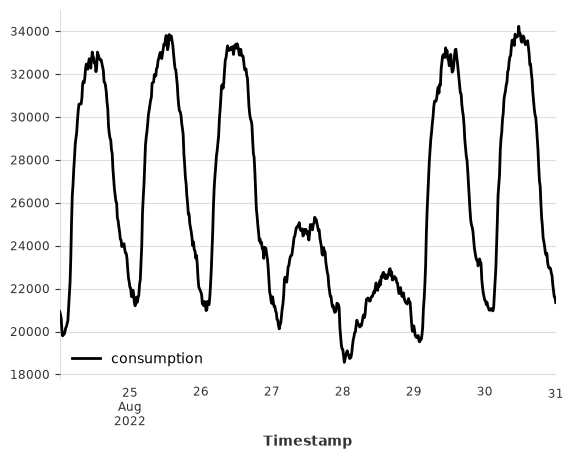

In [6]:
val_energy.plot(label="consumption");

## Model Creation

In the following, we demonstrate model creation using `Chronos2Model`. The same pattern applies to other foundation models -- simply swap the model class.

All foundation models support two types of forecasting outputs:
- **Deterministic** forecasts (**default**): single point estimates for each future time step.
- **Probabilistic** forecasts: multiple samples for each future time step, which can be used to estimate prediction intervals. To enable probabilistic forecasting, set `likelihood=QuantileRegression([...])` when creating the model. The list of quantiles used here must be a subset of the model's supported quantiles. For Chronos-2: `[0.01, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]`.

<details>

<summary><strong>Lookback and Forward Windows</strong></summary>

Under the hood, foundation models are no different from other [Torch Forecasting Models (TFMs)](https://unit8co.github.io/darts/userguide/torch_forecasting_models.html) in Darts and most hyperparameters from TFMs can be applied here as well. In particular, you can control the length of the lookback window and the forward window using the `input_chunk_length` and `output_chunk_length` parameters, respectively.

- `input_chunk_length`: the number of time steps of history the model takes as input when making a forecast. Maximum is **8192** for Chronos-2.
  - if an integer: uses a **fixed-length input window** and will raise errors when some input series are too short.
  - if a tuple of integers `(min_length, max_length)`: it allows **variable input lengths** between `min_length` and `max_length`. This is especially useful when you have a dataset with series of different lengths. Variable input lengths allow you to use the maximum available history for each series.
- `output_chunk_length`: the number of time steps the model outputs in one forward pass. If the forecast horizon is longer than this value, the model consumes its own previous predictions to produce further forecasts. This is known as the autoregressive forecasting. Maximum is **1024** for Chronos-2.

![figure0](https://unit8co.github.io/darts/_images/tfm.png)

See the [Torch Forecasting Models User Guide](https://unit8co.github.io/darts/userguide/torch_forecasting_models.html) for more details.

</details>

<details>

<summary><strong>Model Downloading and Caching</strong></summary>

When creating a foundation model instance for the first time, the pre-trained model checkpoint will be automatically downloaded from Hugging Face Hub and cached locally. Subsequent usage will NOT re-download the files but use the cached version instead.

If you would like to download or load the model checkpoint to a custom directory, set `local_dir` argument when creating the model. For example:

```python
model = Chronos2Model(
    input_chunk_length=168,
    output_chunk_length=24,
    local_dir="path/to/your/directory"
)
```

</details>

<details>

<summary><strong>Using Smaller or Synthetic Variants (Chronos-2)</strong></summary>

Two variants of Chronos-2 are available on HuggingFace Hub:
- [autogluon/chronos-2-small](https://huggingface.co/autogluon/chronos-2-small) : a smaller 28M parameter Chronos-2 model.
- [autogluon/chronos-2-synth](https://huggingface.co/autogluon/chronos-2-synth) : a 120M parameter Chronos-2 model trained on synthetic data only.

To use either of those variants, specify the `hub_model_name` parameter to the desired model ID. For example, to use the synthetic data variant:

```python
model = Chronos2Model(
    input_chunk_length=168,
    output_chunk_length=24,
    hub_model_name="autogluon/chronos-2-small",
    hub_model_revision=None, # e.g., branch, tag, or commit ID
)
```

</details>

Foundation models in Darts support **variable-length input windows**, meaning the model is able to consume and produce forecasts for inputs (series history) of different lengths.

This can be especially useful if you're working on a dataset that contains a large number of series where some are shorter and others longer. Specifying `input_chunk_length=(min_length, max_length)`, allows the model to handle the short series (of length `>=min_length`) while still using the maximum available history (up to length `<=max_length`) for the longer series.

Even though our example here only deals with a single series, we still show how to enable the variable input lengths.

In [7]:
# use up to 30 days of data to predict next 7 days
model = Chronos2Model(
    input_chunk_length=(1, 30 * 24 * 4),
    output_chunk_length=7 * 24 * 4,
)

Apart from the variable-length input window, foundation models also support **fixed-length input windows** like any other Darts torch model. In this mode, the model only ever receives a history of length `input_chunk_length=fixed_length`. The model will check if all input series are long enough and raise an error if not.

## Model Training
Here, we will call the `fit()` method to "train" the model on the training set. Note that no actual training or fine-tuning will be performed since foundation models are already pre-trained.

In [8]:
model.fit(
    series=train_energy,
    verbose=True,
)

Chronos2Model(output_chunk_shift=0, likelihood=None, hub_model_name=amazon/chronos-2, hub_model_revision=None, local_dir=None, input_chunk_length=(1, 2880), output_chunk_length=672, enable_finetuning=False)

## Forecasting
We now perform a one-shot forecast for the next 7 days. We then compare the forecast against the actual values from the validation set.

Output()

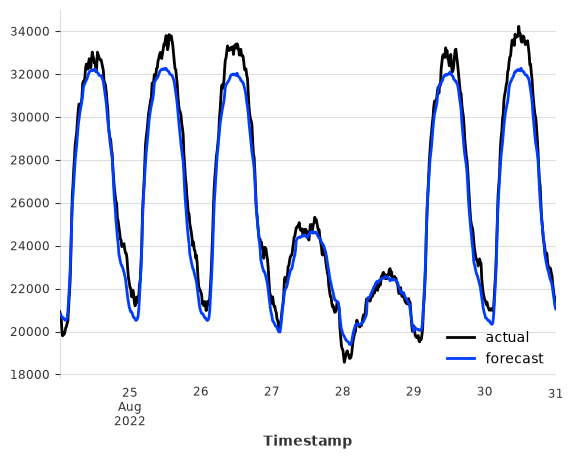

In [9]:
pred = model.predict(
    n=7 * 24 * 4,
    series=train_energy,
)
val_energy.plot(label="actual")
pred.plot(label="forecast");

You can see that the model is able to produce qualitatively accurate forecasts without any training or fine-tuning! Let's evaluate the forecast accuracy using the [Mean Absolute Error (MAE)](https://unit8co.github.io/darts/generated_api/darts.metrics.metrics.html#darts.metrics.metrics.mae) metric.

In [10]:
mae_val = mae(val_energy, pred)
print(f"MAE on validation set: {mae_val:.2f}")

MAE on validation set: 653.57


## Model Fine Tuning

Fine-tuning can be enabled via the `enable_finetuning` model creation parameter. You can find detailed examples in our [fine-tuning examples](https://unit8co.github.io/darts/examples/27-Torch-and-Foundation-Model-Fine-Tuning-examples.html).


## Forecasting with Covariates

<div class="alert alert-info" role="alert">

  This section only applies to foundation models that support covariates (such as `Chronos2Model`, `TimesFM3Model`, `TiRex2Model`, `T0Model`, ...).

</div>

Recall that Chronos-2 supports forecasting with covariates (exogenous variables). Since no training is required, we do not worry about hyperparameter tuning for covariates. Forecasting with covariates is as simple as passing the covariate series to the `fit()` and `predict()` methods!

We use weather variables as future covariates to help forecast the electricity consumption. We then compare the forecast (with and without covariates) against the actual values from the validation set.

<div class="alert alert-warning" role="alert">
  The weather variables here are actual measurements from a weather station and not forecasts (not actual future covariates). The results shown here for demonstration purposes only. In practice, you should supply weather forecasts as future covariates to get realistic results.
</div>

Output()

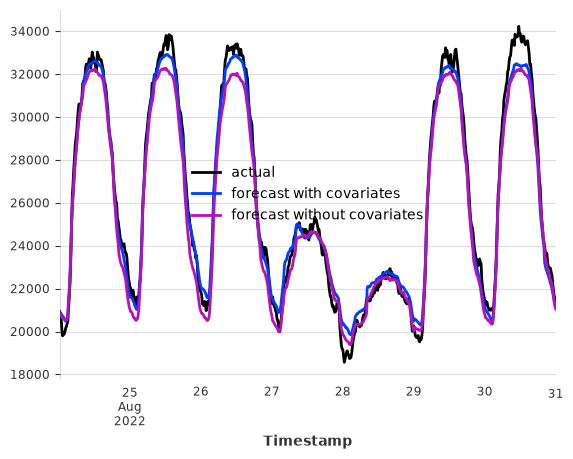

In [11]:
model = Chronos2Model(
    input_chunk_length=30 * 24 * 4,
    output_chunk_length=7 * 24 * 4,
)
model.fit(
    series=train_energy,
    future_covariates=ts_weather,
    verbose=True,
)
pred_cov = model.predict(
    n=7 * 24 * 4,
    series=train_energy,
    future_covariates=ts_weather,
)
val_energy.plot(label="actual")
pred_cov.plot(label="forecast with covariates")
pred.plot(label="forecast without covariates");

With future covariates such as weather, we see that the forecast accuracy has improved on the 7-day horizon! Covariate support from Chronos-2 can be very useful when exogenous variables have a strong influence on the target series.

In [12]:
mae_cov = mae(val_energy, pred_cov)
print(f"MAE on validation set with covariates: {mae_cov:.2f}")

MAE on validation set with covariates: 466.05


## Probabilistic Forecasting
All foundation models support probabilistic forecasting. Here, we show how to perform probabilistic forecasting using [QuantileRegression](https://unit8co.github.io/darts/generated_api/darts.utils.likelihood_models.torch.html#darts.utils.likelihood_models.torch.QuantileRegression) likelihood. The quantiles passed to `QuantileRegression` must be a subset of the model's pre-trained quantiles (see "Model Creation" section above for Chronos-2).

Because sampling with large foundation models can be computationally expensive, we here call `predict()` with `predict_likelihood_parameters=True` to obtain quantile estimates directly without sampling. However, if the forecast horizon is longer than `output_chunk_length` (i.e., auto-regressive forecasting is required), you must call `predict()` with a large enough `num_samples` value (e.g., 1000) to generate probabilistic forecasts via Monte Carlo sampling.

Output()

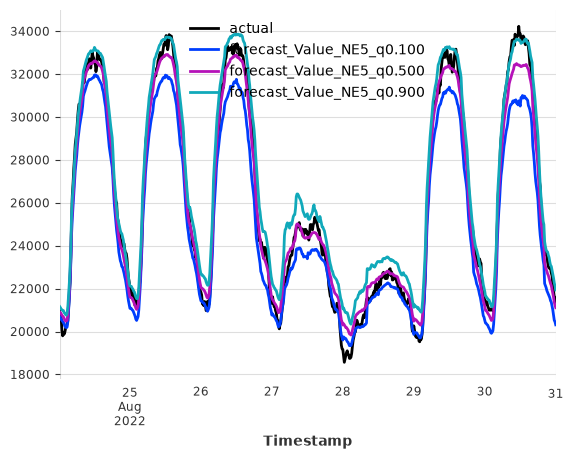

In [13]:
model = Chronos2Model(
    input_chunk_length=30 * 24 * 4,
    output_chunk_length=7 * 24 * 4,
    likelihood=QuantileRegression(quantiles=[0.1, 0.5, 0.9]),
)
model.fit(
    series=train_energy,
    future_covariates=ts_weather,
    verbose=True,
)
pred_prob = model.predict(
    n=7 * 24 * 4,
    series=train_energy,
    future_covariates=ts_weather,
    predict_likelihood_parameters=True,
)
val_energy.plot(label="actual")
pred_prob.plot(label="forecast");

For probabilistic forecasts, we can evaluate the forecast quality by computing the [Mean Interval Coverage (MIC)](https://unit8co.github.io/darts/generated_api/darts.metrics.metrics.html#darts.metrics.metrics.mic) (the share of actuals inside the prediction intervals) and [Mean Interval Width (MIW)](https://unit8co.github.io/darts/generated_api/darts.metrics.metrics.html#darts.metrics.metrics.miw) (the width of the prediction intervals) metrics to evaluate the quality of the prediction intervals.

For MIC, we expect a value close to the nominal coverage of the prediction intervals (i.e., 80% for the (0.1, 0.9) interval). For MIW, lower values indicate narrower prediction intervals and thus better forecast quality when MIC is satisfactory.

In [14]:
mic_prob = mic(val_energy, pred_prob, q_interval=(0.1, 0.9))
miw_prob = miw(val_energy, pred_prob, q_interval=(0.1, 0.9))
print(f"MIC on validation set with covariates: {mic_prob:.2%}")
print(f"MIW on validation set with covariates: {miw_prob:.2f}")

MIC on validation set with covariates: 82.74%
MIW on validation set with covariates: 1719.57


## Final Remarks
Just like other Torch Forecasting Models in Darts, foundation models support historical forecasting (`historical_forecasts()`), backtesting (`backtest()`), residual computation (`residuals()`), custom PyTorch Lightning arguments (`pl_trainer_kwargs`), and more. Check out the following resources to learn more about those topics:
- [Torch Forecasting Models User Guide](https://unit8co.github.io/darts/userguide/torch_forecasting_models.html)
- [Fine Tuning Examples](https://unit8co.github.io/darts/examples/27-Torch-and-Foundation-Model-Fine-Tuning-examples.html)
- [Using Torch Models with GPUs and TPUs](https://unit8co.github.io/darts/userguide/gpu_and_tpu_usage.html)
- [Backtesting: simulate historical forecasting](https://unit8co.github.io/darts/quickstart/00-quickstart.html#Backtesting:-simulate-historical-forecasting)
- [Chronos2Model API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.chronos2_model.html)
- [TimesFM3Model API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.timesfm3_model.html)
- [TimesFM2p5Model API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.timesfm2p5_model.html)
- [TiRexModel API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.tirex_model.html)
- [TiRex2Model API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.tirex2_model.html)
- [T0Model API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.t0_model.html)
- [PatchTSTFMModel API](https://unit8co.github.io/darts/generated_api/darts.models.forecasting.patchtst_fm_model.html)